In [1]:
!pip install -q kagglehub
import os, numpy as np, tensorflow as tf, matplotlib.pyplot as plt, kagglehub
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input,
                                     RandomFlip, RandomRotation, RandomZoom,
                                     Rescaling, GlobalAveragePooling2D)
from tensorflow.keras.preprocessing import image

In [2]:
path = kagglehub.dataset_download("iamsouravbanerjee/indian-food-images-dataset")

def find_root(p):
    best, n = p, 0
    for r, d, f in os.walk(p):
        if len(d) > n and not f:
            best, n = r, len(d)
    return best

DATA_DIR = find_root(path)
print(DATA_DIR)

/kaggle/input/datasets/iamsouravbanerjee/indian-food-images-dataset/Indian Food Images/Indian Food Images


In [3]:
IMG = 128
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="training", seed=42,
    image_size=(IMG, IMG), batch_size=32)
test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, validation_split=0.2, subset="validation", seed=42,
    image_size=(IMG, IMG), batch_size=32)

class_names = train_ds.class_names

def to_arrays(ds):
    xs, ys = [], []
    for x, y in ds:
        xs.append(x.numpy()); ys.append(y.numpy())
    return np.concatenate(xs), np.concatenate(ys)

xtrain, ytrain = to_arrays(train_ds)
xtest, ytest = to_arrays(test_ds)

xtrain = xtrain / 255.0
xtest = xtest / 255.0
print(xtrain.shape, len(class_names))

Found 4000 files belonging to 80 classes.
Using 3200 files for training.
Found 4000 files belonging to 80 classes.
Using 800 files for validation.
(3200, 128, 128, 3) 80


In [4]:
model = Sequential([
    Input(shape=(IMG, IMG, 3)),
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dropout(0.5),
    Dense(256, activation="relu"),
    Dense(len(class_names), activation="softmax")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 80)             │        20,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,536,592 (24.94 MB)

 Trainable params: 6,536,592 (24.94 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

f = model.fit(xtrain, ytrain, epochs=30, validation_data=(xtest, ytest))

Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.0178 - loss: 4.3382 - val_accuracy: 0.0288 - val_loss: 4.2267
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.0409 - loss: 4.1242 - val_accuracy: 0.0575 - val_loss: 4.0072
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.0637 - loss: 3.9249 - val_accuracy: 0.0800 - val_loss: 3.8604
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.0938 - loss: 3.7439 - val_accuracy: 0.0838 - val_loss: 3.7981
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.1094 - loss: 3.6248 - val_accuracy: 0.0913 - val_loss: 3.7558
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.1309 - loss: 3.4996 - val_accuracy: 0.0975 - val_loss: 3.6976
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.1491 - loss: 3.3890 - val_accuracy: 0.1013 - val_loss: 3.8395
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.1813 - loss: 3.2609 - val_accu

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2275 - loss: 4.3064
loss:4.30637788772583, accuracy:0.22750000655651093


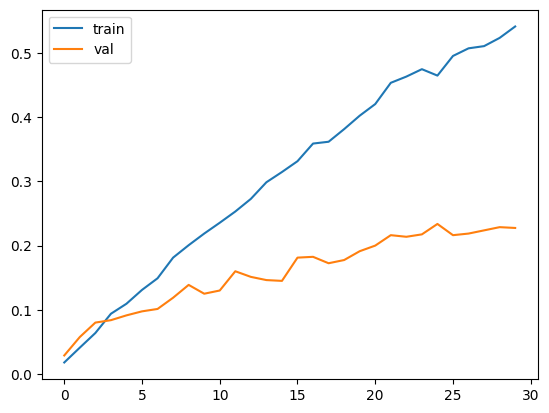

In [6]:
loss, accuracy = model.evaluate(xtest, ytest)
print(f"loss:{loss}, accuracy:{accuracy}")

plt.plot(f.history["accuracy"], label="train")
plt.plot(f.history["val_accuracy"], label="val")
plt.legend(); plt.show()

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


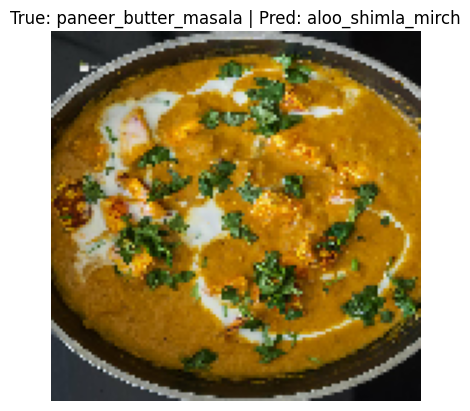

In [7]:
p = model.predict(xtest)
index = 5
plt.imshow(xtest[index])
plt.title(f"True: {class_names[ytest[index]]} | Pred: {class_names[np.argmax(p[index])]}")
plt.axis("off")
plt.show()

In [10]:
img = image.load_img("/kaggle/input/datasets/kishan1314/myfood/food.jpg", target_size=(IMG, IMG))
img_arr = image.img_to_array(img) / 255.0
img_arr = tf.expand_dims(img_arr, axis=0)
p = model.predict(img_arr)
print(class_names[np.argmax(p)])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 274ms/step
chak_hao_kheer
